In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import entropy

MOVEMENT_DIR = Path(
    r"C:\Users\Sheel\OneDrive\Documents\Default Project\data\pads-parkinsons-disease-smartwatch-dataset-1.0.0\pads-parkinsons-disease-smartwatch-dataset-1.0.0\preprocessed\movement"
)

FS = 100.0

tasks = [
    "Relaxed1", "Relaxed2", "RelaxedTask1", "RelaxedTask2",
    "StretchHold", "HoldWeight", "DrinkGlas", "CrossArms",
    "TouchNose", "Entrainment1", "Entrainment2",
]
wrists = ["LeftWrist", "RightWrist"]
sensors = ["Accelerometer", "Gyroscope"]
axes = ["X", "Y", "Z"]
channels = [f"{t}_{w}_{s}_{a}" for t in tasks for w in wrists for s in sensors for a in axes]

print(len(channels), "channels")

132 channels


In [3]:
bin_files = sorted(MOVEMENT_DIR.glob("*_ml.bin"))
ids = np.array([int(f.name.split("_")[0]) for f in bin_files])
movement = np.stack([np.fromfile(f, dtype=np.float32).reshape(len(channels), -1) for f in bin_files])
print("movement:", movement.shape, movement.dtype)

movement: (469, 132, 976) float32


In [4]:
groups = {
    "Healthy": [46, 78, 81, 108, 148, 153, 160, 165, 214, 254, 295, 319, 335, 389, 463],
    "Parkinson's": [4, 95, 109, 113, 175, 206, 226, 249, 345, 347, 362, 365, 395, 406, 442],
    "Essential Tremor": [66, 70, 72, 91, 112, 124, 143, 200, 275, 278, 302, 340, 350, 386, 396],
    "Atypical Parkinsonism": [15, 18, 32, 64, 106, 110, 114, 118, 158, 168, 238, 280, 291, 304, 397],
}
group_names = list(groups)
id_to_group = {pid: g for g, pids in groups.items() for pid in pids}

mask = np.isin(ids, list(id_to_group))
mov = movement[mask]
pids = ids[mask]

channel_df = pd.DataFrame({
    "channel": channels,
    "task": [c.split("_")[0] for c in channels],
    "wrist": [c.split("_")[1] for c in channels],
    "sensor": [c.split("_")[2] for c in channels],
    "axis": [c.split("_")[3] for c in channels],
})

predictor_names = [
    "Relative Tremor Power", "Harmonic Power Ratio", "Movement Amplitude",
    "Acceleration Norm", "Jerk", "Spectral Entropy", "Primary Frequency Component",
]

def stream_predictors(acc_norm):
    n = acc_norm.shape[1]
    freqs = np.fft.rfftfreq(n, d=1 / FS)
    dfreq = FS / n
    power = np.abs(np.fft.rfft(acc_norm, axis=1)) ** 2
    power_nn = power[:, 1:]
    primary_bin = np.argmax(power_nn, axis=1) + 1
    primary_freq = freqs[primary_bin]
    spec_entropy = entropy(power_nn, axis=1)
    jerk = np.diff(acc_norm, axis=1)
    tremor_band = ((freqs >= 3) & (freqs <= 8))[1:]
    rel_tremor_power = power_nn[:, tremor_band].sum(axis=1) / power_nn.sum(axis=1)
    harm_bins = np.stack([
        np.clip(np.round(k * freqs[primary_bin] / dfreq).astype(int), 0, len(freqs) - 1)
        for k in (2, 3)
    ], axis=1)
    rows = np.arange(power.shape[0])[:, None]
    harmonic_power = power[rows, harm_bins].sum(axis=1)
    main_power = power[np.arange(power.shape[0]), primary_bin]
    return {
        "Relative Tremor Power": rel_tremor_power,
        "Harmonic Power Ratio": harmonic_power / main_power,
        "Movement Amplitude": np.ptp(acc_norm, axis=1),
        "Acceleration Norm": acc_norm.mean(axis=1),
        "Jerk": jerk.mean(axis=1),
        "Spectral Entropy": spec_entropy,
        "Primary Frequency Component": primary_freq,
    }

stream_feats = []
feature_names = []
for (task, wrist), grp in channel_df.groupby(["task", "wrist"]):
    acc = mov[:, grp.index[grp["sensor"] == "Accelerometer"].tolist(), :]
    acc_norm = np.linalg.norm(acc, axis=1)
    stream = stream_predictors(acc_norm)
    for name in predictor_names:
        stream_feats.append(stream[name])
        feature_names.append(f"{task}_{wrist}_{name}")

X_model = np.column_stack(stream_feats)
y_labels = np.array([id_to_group[p] for p in pids])
y_model = pd.Categorical(y_labels, categories=group_names).codes

print("X:", X_model.shape, "| y:", y_model.shape)
print(pd.Series(y_labels).value_counts().to_string())

X: (60, 154) | y: (60,)
Parkinson's              15
Atypical Parkinsonism    15
Healthy                  15
Essential Tremor         15


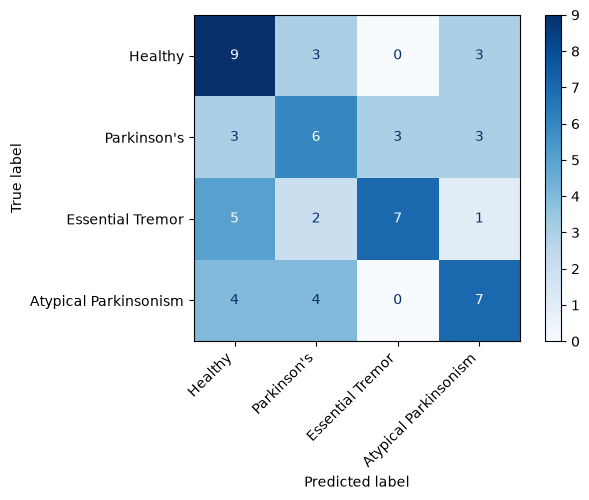

4-class CV accuracy: 0.48
                       precision    recall  f1-score   support

              Healthy       0.43      0.60      0.50        15
          Parkinson's       0.40      0.40      0.40        15
     Essential Tremor       0.70      0.47      0.56        15
Atypical Parkinsonism       0.50      0.47      0.48        15

             accuracy                           0.48        60
            macro avg       0.51      0.48      0.49        60
         weighted avg       0.51      0.48      0.49        60

X shape: (60, 154)
Number of participants: 60

Class counts:
(array([0, 1, 2, 3], dtype=int8), array([15, 15, 15, 15]))


In [6]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(solver="saga", l1_ratio=0.5, max_iter=5000, random_state=0)),
])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
predictions = cross_val_predict(
    model_pipeline,
    X_model,
    y_model,
    cv=cv,
    method="predict",
)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_model, predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=group_names,
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.setp(disp.ax_.get_xticklabels(), ha="right")
plt.subplots_adjust(bottom=0.2)
plt.show()

cv_accuracy = accuracy_score(y_model, predictions)
print(f"4-class CV accuracy: {cv_accuracy:.2f}")
print(
    classification_report(
        y_model,
        predictions,
        target_names=group_names,
        zero_division=0,
    )
)
print("X shape:", X_model.shape)
print("Number of participants:", len(y_model))
print("\nClass counts:")
print(np.unique(y_model, return_counts=True))

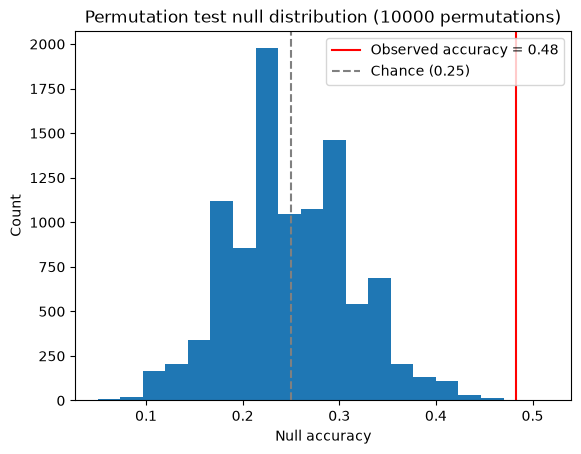

Observed accuracy: 0.483
Null mean: 0.249 | Null std: 0.064
Permutation p-value: 0.0006
scikit-learn p-value: 0.0006


In [7]:
import matplotlib.pyplot as plt
from sklearn.model_selection import permutation_test_score

score, permutation_scores, pvalue = permutation_test_score(
    model_pipeline,
    X_model,
    y_model,
    scoring="accuracy",
    cv=cv,
    n_permutations=10000,
    n_jobs=-1,
    random_state=42,
)

plt.hist(permutation_scores, bins=20, density=False)
plt.axvline(score, color="red", label=f"Observed accuracy = {score:.2f}")
plt.axvline(0.25, color="gray", linestyle="--", label="Chance (0.25)")
plt.xlabel("Null accuracy")
plt.ylabel("Count")
plt.title("Permutation test null distribution (10000 permutations)")
plt.legend()
plt.show()

# Manual p-value from the null distribution:
# proportion of permuted accuracies at least as extreme as the observed accuracy
manual_p_value = (np.sum(permutation_scores >= score) + 1) / (len(permutation_scores) + 1)

print(f"Observed accuracy: {score:.3f}")
print(f"Null mean: {permutation_scores.mean():.3f} | Null std: {permutation_scores.std():.3f}")
print(f"Permutation p-value: {manual_p_value:.4f}")
print(f"scikit-learn p-value: {pvalue:.4f}")